In [1]:
# import library
import os, json, time
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

Path("data").mkdir(exist_ok=True)

In [2]:
# fungsi untuk mengambil API
def ambil_api(url, params=None, coba=3, jeda=2):
    for i in range(coba):
        r = requests.get(url, params=params, timeout=15)
        if r.status_code == 200:
            return r.json()
        if r.status_code in (429, 500, 502, 503):
            time.sleep(jeda * (i + 1))
            continue
        r.raise_for_status()
    raise RuntimeError(f"Gagal setelah {coba} percobaan (status {r.status_code})")

# fungsi untuk mengambil isi halaman
def ambil_halaman(url, params=None, param_halaman="page", maks=5, jeda=1):
    semua = []
    for p in range(1, maks + 1):
        d = ambil_api(url, {**(params or {}), param_halaman: p})
        if not d:
            break
        semua.extend(d if isinstance(d, list) else [d])
        time.sleep(jeda)
    return semua

# fungsi untuk memindahkah data API dan Halaman kedalam Tabel
def ke_tabel(data, jalur=None):
    return pd.json_normalize(data, record_path=jalur, sep="_")

# fungsi standar untuk preprocesing data
def bersihkan(df):
    df = df.copy()
    df.columns = df.columns.str.replace(r"\W+", "_", regex=True).str.strip("_").str.lower()
    df = df.apply(lambda s: s.map(lambda v: json.dumps(v) if isinstance(v, (list, dict)) else v))
    df = df.drop_duplicates()
    for c in df.columns:
        if any(k in c for k in ("time", "waktu", "date", "tanggal")) or c.endswith("ts"):
            df[c] = pd.to_datetime(df[c], errors="coerce", utc=True)
    return df

# fungsi untuk menyimpan data dari tabek kedalam bentuk JSON dan CSV
def simpan(data, df, nama):
    Path(f"data/{nama}.json").write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding="utf-8")
    df.to_csv(f"data/{nama}.csv", index=False, encoding="utf-8")
    print(f"Tersimpan: data/{nama}.json dan data/{nama}.csv")

# fungsi untuk menampilkan ringkasan data
def ringkas(df):
    print("Ukuran:", df.shape)
    print("\nTipe data dan nilai hilang:")
    display(pd.DataFrame({"tipe": df.dtypes.astype(str), "hilang": df.isna().sum()}))
    print("\nStatistik deskriptif:")
    display(df.describe(include="all").T.head(15))

DATA CUACA PEKANBARU
Dimensi data: (6576, 16)

Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6576 entries, 0 to 6575
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   time                     6576 non-null   datetime64[ns]
 1   temperature_2m           6576 non-null   float64       
 2   dew_point_2m             6576 non-null   float64       
 3   relative_humidity_2m     6576 non-null   int64         
 4   pressure_msl             6576 non-null   float64       
 5   cloud_cover              6576 non-null   int64         
 6   cloud_cover_low          6576 non-null   int64         
 7   wind_speed_10m           6576 non-null   float64       
 8   wind_direction_10m       6576 non-null   int64         
 9   wind_gusts_10m           6576 non-null   float64       
 10  rain                     6576 non-null   float64       
 11  precipitation            6576 no

,time,temperature_2m,dew_point_2m,relative_humidity_2m,pressure_msl,cloud_cover,cloud_cover_low,wind_speed_10m,wind_direction_10m,wind_gusts_10m,rain,precipitation,shortwave_radiation,vapour_pressure_deficit,boundary_layer_height,soil_moisture_0_to_7cm
0,2026-01-18 00:00:00,23.9,22.9,94,1008.8,100,6,4.0,297,20.5,0.1,0.1,0.0,0.18,40.0,0.246
1,2026-01-18 01:00:00,24.2,22.8,92,1008.4,100,14,2.8,325,11.5,0.0,0.0,0.0,0.24,50.0,0.199
2,2026-01-18 02:00:00,24.2,22.8,92,1007.4,100,9,3.4,264,7.2,0.0,0.0,0.0,0.25,45.0,0.199
3,2026-01-18 03:00:00,24.3,23.0,92,1007.1,100,1,4.5,355,8.6,0.0,0.0,0.0,0.23,65.0,0.199
4,2026-01-18 04:00:00,23.4,22.4,94,1007.4,100,17,8.4,37,16.6,0.1,0.1,0.0,0.16,135.0,0.200



Jumlah missing value:


,0
time,0
temperature_2m,0
dew_point_2m,0
relative_humidity_2m,0
pressure_msl,0
cloud_cover,0
cloud_cover_low,0
wind_speed_10m,0
wind_direction_10m,0
wind_gusts_10m,0



Satuan setiap variabel:
{'time': 'iso8601', 'temperature_2m': '°C', 'dew_point_2m': '°C', 'relative_humidity_2m': '%', 'pressure_msl': 'hPa', 'cloud_cover': '%', 'cloud_cover_low': '%', 'wind_speed_10m': 'km/h', 'wind_direction_10m': '°', 'wind_gusts_10m': 'km/h', 'rain': 'mm', 'precipitation': 'mm', 'shortwave_radiation': 'W/m²', 'vapour_pressure_deficit': 'kPa', 'boundary_layer_height': 'm', 'soil_moisture_0_to_7cm': 'm³/m³'}
Data berhasil disimpan: data_cuaca_pekanbaru.csv

DATASET KLASIFIKASI HUJAN
Jumlah data awal : 6576
Jumlah data akhir: 6573
Jumlah prediktor : 19
Jumlah target    : 1
Observasi terhapus: 3

DISTRIBUSI KELAS


,Kategori,Jumlah,Persentase (%)
0,Tidak Hujan (0),4490,68.309752
1,Hujan (1),2083,31.690248



PEMERIKSAAN DATA
Duplikasi waktu: 0
Missing value: 0
Jumlah kelas: 2
Periode: 2026-01-18 02:00:00 sampai 2026-10-18 22:00:00

Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
temperature_2m,6573.0,2.784442e+01,2.890368,22.40,25.400000,2.730000e+01,30.200000,36.00
relative_humidity_2m,6573.0,7.960262e+01,15.361995,33.00,68.000000,8.300000e+01,93.000000,100.00
dew_point_2m,6573.0,2.362026e+01,1.391503,16.10,23.000000,2.390000e+01,24.600000,27.40
pressure_msl,6573.0,1.010318e+03,1.924897,1003.90,1009.100000,1.010400e+03,1011.700000,1015.70
cloud_cover,6573.0,7.933592e+01,28.141641,0.00,66.000000,9.500000e+01,100.000000,100.00
cloud_cover_low,6573.0,1.109615e+01,19.784810,0.00,0.000000,4.000000e+00,13.000000,100.00
wind_speed_10m,6573.0,6.201537e+00,3.061674,0.00,4.000000,6.000000e+00,8.100000,19.30
wind_gusts_10m,6573.0,1.725815e+01,7.391129,0.70,11.900000,1.620000e+01,21.600000,51.10
wind_direction_sin,6573.0,2.323898e-01,0.641392,-1.00,-0.275637,4.539905e-01,0.766044,1.00
wind_direction_cos,6573.0,-1.824419e-01,0.708142,-1.00,-0.838671,-4.226183e-01,0.529919,1.00


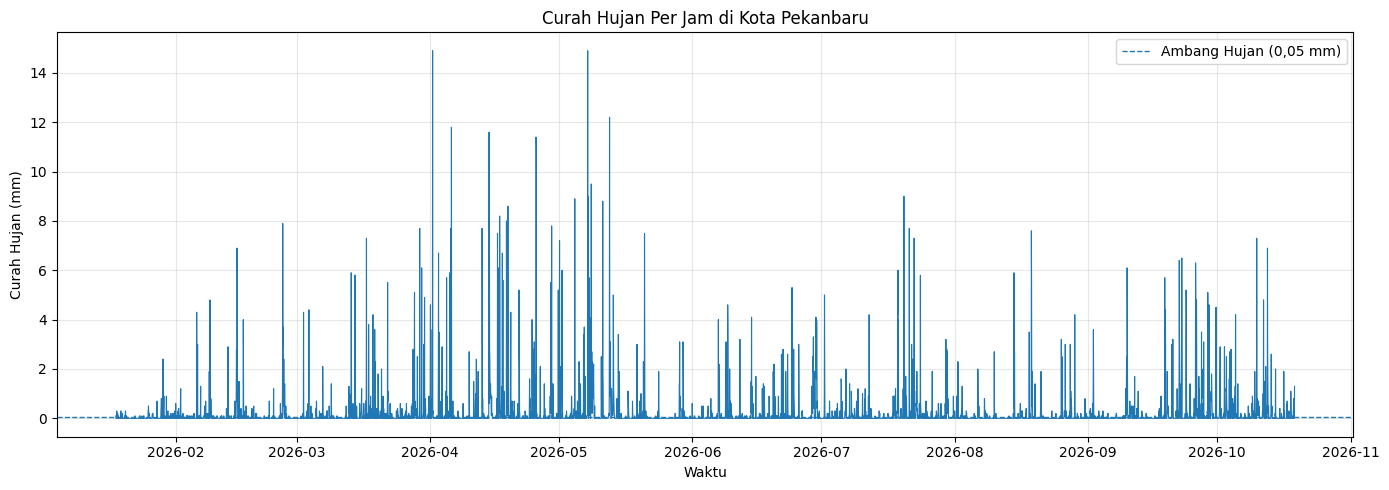

<Figure size 700x500 with 0 Axes>

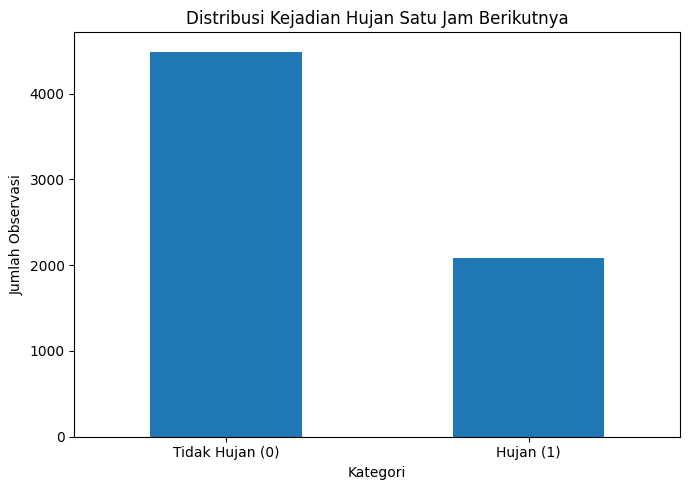


Dataset berhasil disimpan!
Nama file: dataset_klasifikasi_hujan_pekanbaru.csv


,time,temperature_2m,relative_humidity_2m,dew_point_2m,pressure_msl,cloud_cover,cloud_cover_low,wind_speed_10m,wind_gusts_10m,wind_direction_sin,...,shortwave_radiation,vapour_pressure_deficit,boundary_layer_height,soil_moisture_0_to_7cm,rain_prev_1h,rain_prev_2h,rain_prev_3h,hour_sin,hour_cos,target_hujan_next_1h
0,2026-01-18 02:00:00,24.2,92,22.8,1007.4,100,9,3.4,7.2,-0.994522,...,0.0,0.25,45.0,0.199,0.0,0.0,0.1,0.500000,8.660254e-01,0
1,2026-01-18 03:00:00,24.3,92,23.0,1007.1,100,1,4.5,8.6,-0.087156,...,0.0,0.23,65.0,0.199,0.0,0.0,0.0,0.707107,7.071068e-01,1
2,2026-01-18 04:00:00,23.4,94,22.4,1007.4,100,17,8.4,16.6,0.601815,...,0.0,0.16,135.0,0.200,0.1,0.0,0.0,0.866025,5.000000e-01,1
3,2026-01-18 05:00:00,22.9,93,21.8,1007.6,99,85,6.0,15.8,0.422618,...,0.0,0.19,190.0,0.203,0.3,0.1,0.0,0.965926,2.588190e-01,1
4,2026-01-18 06:00:00,22.8,95,22.0,1007.8,100,45,7.5,14.0,0.601815,...,0.0,0.14,205.0,0.205,0.2,0.3,0.1,1.000000,6.123234e-17,0
5,2026-01-18 07:00:00,24.3,94,23.3,1008.0,99,19,9.8,13.7,0.766044,...,15.0,0.17,240.0,0.190,0.0,0.2,0.3,0.965926,-2.588190e-01,1
6,2026-01-18 08:00:00,25.1,90,23.3,1008.7,84,34,8.9,23.0,0.615661,...,157.0,0.32,315.0,0.190,0.1,0.0,0.2,0.866025,-5.000000e-01,1
7,2026-01-18 09:00:00,26.5,82,23.2,1009.0,89,33,8.1,21.6,0.629320,...,371.0,0.62,425.0,0.189,0.1,0.1,0.0,0.707107,-7.071068e-01,1
8,2026-01-18 10:00:00,28.0,73,22.8,1009.1,100,26,9.7,25.6,0.422618,...,524.0,1.00,600.0,0.188,0.2,0.1,0.1,0.500000,-8.660254e-01,1
9,2026-01-18 11:00:00,29.4,67,22.7,1008.7,99,18,7.2,25.2,0.104528,...,720.0,1.33,775.0,0.185,0.1,0.2,0.1,0.258819,-9.659258e-01,0


In [3]:

# ============================================================
# KLASIFIKASI KEJADIAN HUJAN PEKANBARU
# Persiapan Dataset untuk SVM dan ANN
# Sumber: Open-Meteo Historical Weather API
# ============================================================

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

# ============================================================
# 1. FUNGSI PENGAMBILAN DATA API
# ============================================================

def ambil_api(url, params):
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    data = response.json()

    if data.get("error"):
        raise ValueError(data.get("reason", "API error"))

    return data


# ============================================================
# 2. FUNGSI PEMBERSIHAN DATA
# ============================================================

def bersihkan(df):
    df = df.copy()

    df["time"] = pd.to_datetime(
        df["time"], errors="coerce"
    )

    kolom_numerik = [
        kolom for kolom in df.columns
        if kolom != "time"
    ]

    df[kolom_numerik] = df[kolom_numerik].apply(
        pd.to_numeric, errors="coerce"
    )

    df = (
        df.dropna(subset=["time"])
          .drop_duplicates(subset=["time"])
          .sort_values("time")
          .reset_index(drop=True)
    )

    return df


# ============================================================
# 3. FUNGSI RINGKASAN DATA
# ============================================================

def ringkas(df):
    print("Dimensi data:", df.shape)

    print("\nInformasi data:")
    df.info()

    print("\nLima observasi pertama:")
    display(df.head())

    print("\nJumlah missing value:")
    display(df.isnull().sum())


# ============================================================
# 4. FUNGSI MENYIMPAN DATA
# ============================================================

def simpan(data_api, df, nama):
    with open(
        f"{nama}_raw.json", "w", encoding="utf-8"
    ) as file:
        json.dump(data_api, file, ensure_ascii=False, indent=4)

    df.to_csv(f"{nama}.csv", index=False)

    print(f"Data berhasil disimpan: {nama}.csv")


# ============================================================
# 5. PARAMETER OPEN-METEO
# ============================================================

params = {
    "latitude": 0.5104,
    "longitude": 101.4383,

    "hourly": ",".join([
        # Suhu
        "temperature_2m",
        "dew_point_2m",

        # Kelembapan
        "relative_humidity_2m",

        # Tekanan udara
        "pressure_msl",

        # Tutupan awan
        "cloud_cover",
        "cloud_cover_low",

        # Angin
        "wind_speed_10m",
        "wind_direction_10m",
        "wind_gusts_10m",

        # Presipitasi
        "rain",
        "precipitation",

        # Radiasi matahari
        "shortwave_radiation",

        # Variabel atmosfer
        "vapour_pressure_deficit",
        "boundary_layer_height",

        # Kondisi tanah
        "soil_moisture_0_to_7cm"
    ]),

    "timezone": "Asia/Jakarta",
    "temperature_unit": "celsius",
    "wind_speed_unit": "kmh",
    "precipitation_unit": "mm",

    "start_date": "2026-01-18",
    "end_date": "2026-10-18"
}


# ============================================================
# 6. MENGAMBIL DATA CUACA
# ============================================================

url = "https://archive-api.open-meteo.com/v1/archive"

cuaca = ambil_api(url, params)

df_b = pd.DataFrame(cuaca["hourly"])
df_b = bersihkan(df_b)

print("DATA CUACA PEKANBARU")
ringkas(df_b)

print("\nSatuan setiap variabel:")
print(cuaca["hourly_units"])

simpan(
    cuaca,
    df_b,
    "data_cuaca_pekanbaru"
)


# ============================================================
# 7. FEATURE ENGINEERING
# ============================================================

df_model = df_b.copy()


# ------------------------------------------------------------
# A. Transformasi arah angin
# ------------------------------------------------------------

arah_rad = np.deg2rad(df_model["wind_direction_10m"])

df_model["wind_direction_sin"] = np.sin(arah_rad)
df_model["wind_direction_cos"] = np.cos(arah_rad)


# ------------------------------------------------------------
# B. Riwayat curah hujan
# ------------------------------------------------------------

# Rain pada waktu t merupakan akumulasi hujan
# selama satu jam yang berakhir pada waktu t.

df_model["rain_prev_1h"] = df_model["rain"]
df_model["rain_prev_2h"] = df_model["rain"].shift(1)
df_model["rain_prev_3h"] = df_model["rain"].shift(2)


# ------------------------------------------------------------
# C. Transformasi waktu siklik
# ------------------------------------------------------------

jam = df_model["time"].dt.hour

df_model["hour_sin"] = np.sin(
    2 * np.pi * jam / 24
)

df_model["hour_cos"] = np.cos(
    2 * np.pi * jam / 24
)


# ============================================================
# 8. MEMBENTUK VARIABEL TARGET
# ============================================================

# Rain pada t+1 mewakili curah hujan
# selama interval satu jam setelah waktu t.

df_model["rain_next_1h_mm"] = (
    df_model["rain"].shift(-1)
)

# Ambang minimal curah hujan
BATAS_HUJAN = 0.05  # mm

# Klasifikasi kejadian hujan
# 0 = Tidak Hujan (< 0.05 mm)
# 1 = Hujan (>= 0.05 mm)

df_model["target_hujan_next_1h"] = np.where(
    df_model["rain_next_1h_mm"].notna(),
    (
        df_model["rain_next_1h_mm"] >= BATAS_HUJAN
    ).astype(int),
    np.nan
)


# ============================================================
# 9. MENENTUKAN VARIABEL PREDIKTOR (X)
# ============================================================

fitur = [
    "temperature_2m",
    "relative_humidity_2m",
    "dew_point_2m",
    "pressure_msl",
    "cloud_cover",
    "cloud_cover_low",
    "wind_speed_10m",
    "wind_gusts_10m",
    "wind_direction_sin",
    "wind_direction_cos",
    "shortwave_radiation",
    "vapour_pressure_deficit",
    "boundary_layer_height",
    "soil_moisture_0_to_7cm",
    "rain_prev_1h",
    "rain_prev_2h",
    "rain_prev_3h",
    "hour_sin",
    "hour_cos"
]

target = "target_hujan_next_1h"


# ============================================================
# 10. MEMBENTUK DATASET KLASIFIKASI
# ============================================================

kolom_final = ["time"] + fitur + [target]

df_klasifikasi = df_model[kolom_final].copy()

jumlah_awal = len(df_klasifikasi)

df_klasifikasi = (
    df_klasifikasi
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
    .reset_index(drop=True)
)

df_klasifikasi[target] = (
    df_klasifikasi[target].astype(int)
)

print("\nDATASET KLASIFIKASI HUJAN")
print("Jumlah data awal :", jumlah_awal)
print("Jumlah data akhir:", len(df_klasifikasi))
print("Jumlah prediktor :", len(fitur))
print("Jumlah target    :", 1)
print("Observasi terhapus:", jumlah_awal - len(df_klasifikasi))


# ============================================================
# 11. DISTRIBUSI KELAS TARGET
# ============================================================

distribusi = (
    df_klasifikasi[target]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

persentase = (
    distribusi / distribusi.sum() * 100
)

hasil_kelas = pd.DataFrame({
    "Kategori": ["Tidak Hujan (0)", "Hujan (1)"],
    "Jumlah": distribusi.values,
    "Persentase (%)": persentase.values
})

print("\nDISTRIBUSI KELAS")
display(hasil_kelas)


# ============================================================
# 12. PEMERIKSAAN KUALITAS DATA
# ============================================================

print("\nPEMERIKSAAN DATA")

print(
    "Duplikasi waktu:",
    df_klasifikasi["time"].duplicated().sum()
)

print(
    "Missing value:",
    df_klasifikasi.isnull().sum().sum()
)

print(
    "Jumlah kelas:",
    df_klasifikasi[target].nunique()
)

print(
    "Periode:",
    df_klasifikasi["time"].min(),
    "sampai",
    df_klasifikasi["time"].max()
)

print("\nStatistik deskriptif:")
display(df_klasifikasi[fitur].describe().T)


# ============================================================
# 13. VISUALISASI CURAH HUJAN
# ============================================================

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_model["time"],
    df_model["rain"],
    linewidth=0.8
)

ax.axhline(
    y=BATAS_HUJAN,
    linestyle="--",
    linewidth=1,
    label="Ambang Hujan (0,05 mm)"
)

ax.set_title("Curah Hujan Per Jam di Kota Pekanbaru")
ax.set_xlabel("Waktu")
ax.set_ylabel("Curah Hujan (mm)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 14. VISUALISASI DISTRIBUSI TARGET
# ============================================================

plt.figure(figsize=(7, 5))

hasil_kelas.plot(
    x="Kategori",
    y="Jumlah",
    kind="bar",
    legend=False,
    figsize=(7, 5)
)

plt.title("Distribusi Kejadian Hujan Satu Jam Berikutnya")
plt.xlabel("Kategori")
plt.ylabel("Jumlah Observasi")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# ============================================================
# 15. MENYIMPAN DATASET FINAL
# ============================================================

df_klasifikasi.to_csv(
    "dataset_klasifikasi_hujan_pekanbaru.csv",
    index=False
)

hasil_kelas.to_csv(
    "distribusi_kelas_hujan.csv",
    index=False
)

print("\nDataset berhasil disimpan!")

print(
    "Nama file: dataset_klasifikasi_hujan_pekanbaru.csv"
)

display(df_klasifikasi.head(10))
